
# Sales Data Analysis

## Project Overview

This project explores sales transaction data using Python and Pandas.
It examines revenue patterns across months, products, and regions
to summarize sales performance and identify useful trends.

## Objectives

- Inspect and validate the sales dataset.
- Clean and prepare the data for analysis.
- Calculate total revenue and units sold.
- Compare sales performance across months, products, and regions.
- Visualize results and interpret the findings.
- Document the limitations of the dataset.

## Tools Used

- Python
- Pandas
- Matplotlib
- Jupyter Notebook


In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv")

df.head()

,Order Date,Product,Quantity,Price,Region
0,2024-01-05,Laptop,2,50000,North
1,2024-01-10,Mobile,3,20000,South
2,2024-02-15,Tablet,1,30000,East
3,2024-02-20,Laptop,1,50000,West
4,2024-03-05,Mobile,4,20000,North


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (8, 5)

Column names:
['Order Date', 'Product', 'Quantity', 'Price', 'Region']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Order Date  8 non-null      str  
 1   Product     8 non-null      str  
 2   Quantity    8 non-null      int64
 3   Price       8 non-null      int64
 4   Region      8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique products:", df["Product"].unique())
print("\nUnique regions:", df["Region"].unique())

print("\nSummary statistics:")
display(df.describe())

Missing values in each column:
Order Date    0
Product       0
Quantity      0
Price         0
Region        0
dtype: int64

Duplicate rows: 0

Unique products: <StringArray>
['Laptop', 'Mobile', 'Tablet']
Length: 3, dtype: str

Unique regions: <StringArray>
['North', 'South', 'East', 'West']
Length: 4, dtype: str

Summary statistics:


,Quantity,Price
count,8.000000,8.000000
mean,2.125000,33750.000000
std,1.125992,14078.859532
min,1.000000,20000.000000
25%,1.000000,20000.000000
50%,2.000000,30000.000000
75%,3.000000,50000.000000
max,4.000000,50000.000000


In [4]:
# Convert order dates into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Check for invalid dates
print("Invalid dates:", df["Order Date"].isna().sum())

# Check quantities and prices
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["Price"] <= 0).sum())

# Confirm the updated data types
print("\nUpdated data types:")
print(df.dtypes)

Invalid dates: 0
Invalid quantities: 0
Invalid prices: 0

Updated data types:
Order Date    datetime64[us]
Product                  str
Quantity               int64
Price                  int64
Region                   str
dtype: object


In [5]:
# Calculate revenue for each transaction
df["Total Sales"] = df["Quantity"] * df["Price"]

# Extract the month from each order date
df["Month"] = df["Order Date"].dt.month_name()

# Display the updated dataset
display(df)

,Order Date,Product,Quantity,Price,Region,Total Sales,Month
0,2024-01-05,Laptop,2,50000,North,100000,January
1,2024-01-10,Mobile,3,20000,South,60000,January
2,2024-02-15,Tablet,1,30000,East,30000,February
3,2024-02-20,Laptop,1,50000,West,50000,February
4,2024-03-05,Mobile,4,20000,North,80000,March
5,2024-03-18,Tablet,2,30000,South,60000,March
6,2024-04-10,Laptop,3,50000,East,150000,April
7,2024-04-22,Mobile,1,20000,West,20000,April


In [6]:
# Calculate overall sales performance
total_revenue = df["Total Sales"].sum()
total_units_sold = df["Quantity"].sum()
total_transactions = len(df)

print(f"Total revenue: ₹{total_revenue:,.0f}")
print(f"Total units sold: {total_units_sold}")
print(f"Total transactions: {total_transactions}")

Total revenue: ₹550,000
Total units sold: 17
Total transactions: 8


In [7]:
# Calculate revenue for each month
monthly_sales = df.groupby("Month")["Total Sales"].sum()

# Arrange months in calendar order
month_order = ["January", "February", "March", "April"]
monthly_sales = monthly_sales.reindex(month_order)

# Calculate month-to-month percentage change
monthly_change = monthly_sales.pct_change() * 100

# Display the results
monthly_summary = monthly_sales.to_frame(name="Revenue")
monthly_summary["Change (%)"] = monthly_change.round(2)

display(monthly_summary)

,Revenue,Change (%)
Month,,
January,160000,NaN
February,80000,-50.00
March,140000,75.00
April,170000,21.43


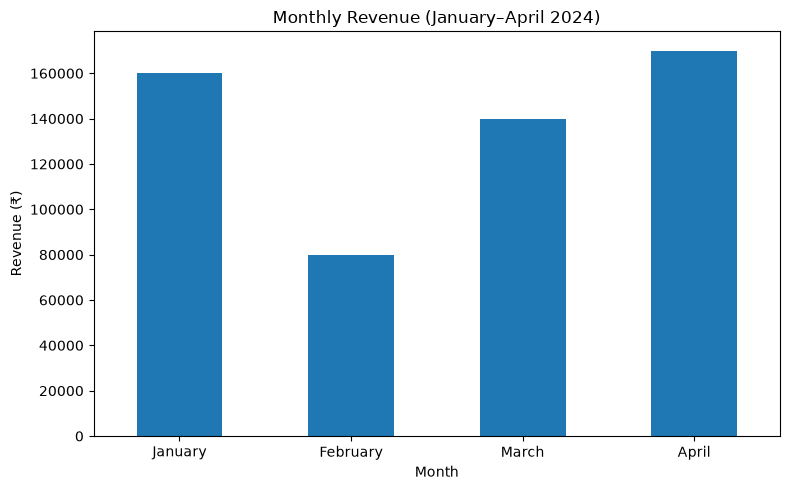

In [8]:
import matplotlib.pyplot as plt

# Plot monthly revenue
ax = monthly_sales.plot(kind="bar", figsize=(8, 5))

ax.set_title("Monthly Revenue (January–April 2024)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (₹)")
ax.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Calculate revenue and units sold for each product
product_summary = df.groupby("Product").agg(
    Total_Revenue=("Total Sales", "sum"),
    Units_Sold=("Quantity", "sum"),
    Transactions=("Product", "count")
)

# Sort products by revenue, highest first
product_summary = product_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

display(product_summary)

,Total_Revenue,Units_Sold,Transactions
Product,,,
Laptop,300000,6,3
Mobile,160000,8,3
Tablet,90000,3,2


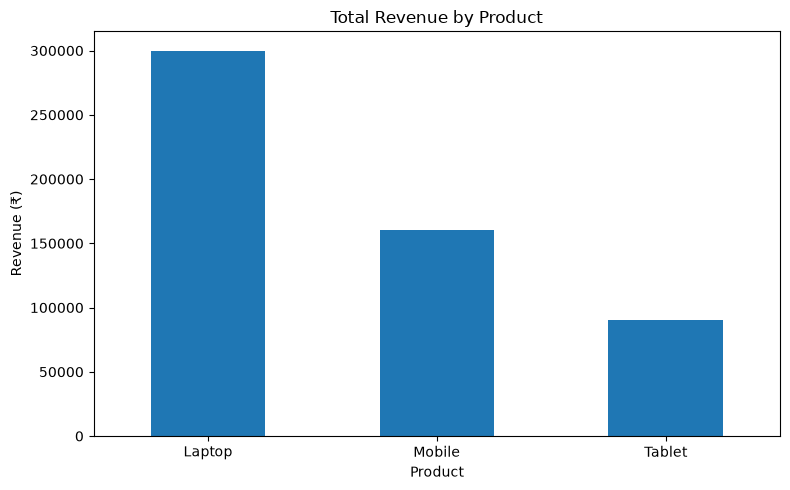

In [10]:
# Plot revenue by product
ax = product_summary["Total_Revenue"].plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Total Revenue by Product")
ax.set_xlabel("Product")
ax.set_ylabel("Revenue (₹)")
ax.ticklabel_format(axis="y", style="plain")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Calculate revenue and units sold for each region
region_summary = df.groupby("Region").agg(
    Total_Revenue=("Total Sales", "sum"),
    Units_Sold=("Quantity", "sum"),
    Transactions=("Region", "count")
)

# Sort regions by revenue, highest first
region_summary = region_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

display(region_summary)

,Total_Revenue,Units_Sold,Transactions
Region,,,
East,180000,4,2
North,180000,6,2
South,120000,5,2
West,70000,2,2


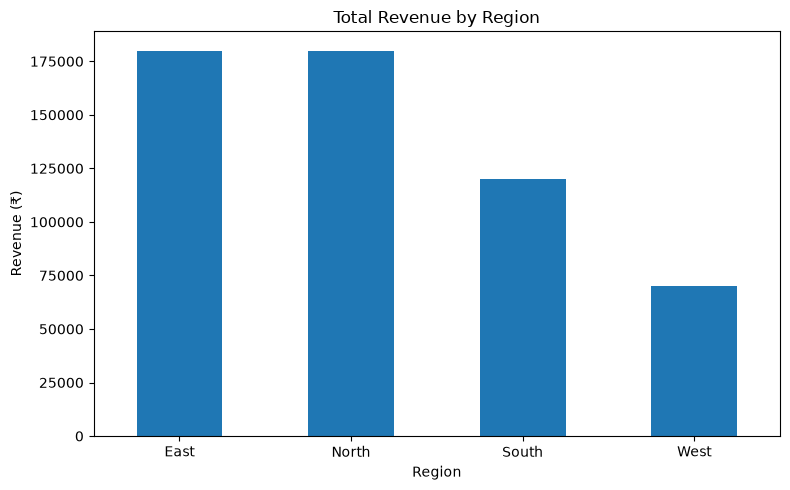

In [12]:
# Plot revenue by region
ax = region_summary["Total_Revenue"].plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Total Revenue by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Revenue (₹)")
ax.ticklabel_format(axis="y", style="plain")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Calculate each region's percentage contribution to total revenue
region_summary["Revenue_Share_%"] = (
    region_summary["Total_Revenue"] / total_revenue * 100
).round(2)

display(region_summary)

,Total_Revenue,Units_Sold,Transactions,Revenue_Share_%
Region,,,,
East,180000,4,2,32.73
North,180000,6,2,32.73
South,120000,5,2,21.82
West,70000,2,2,12.73


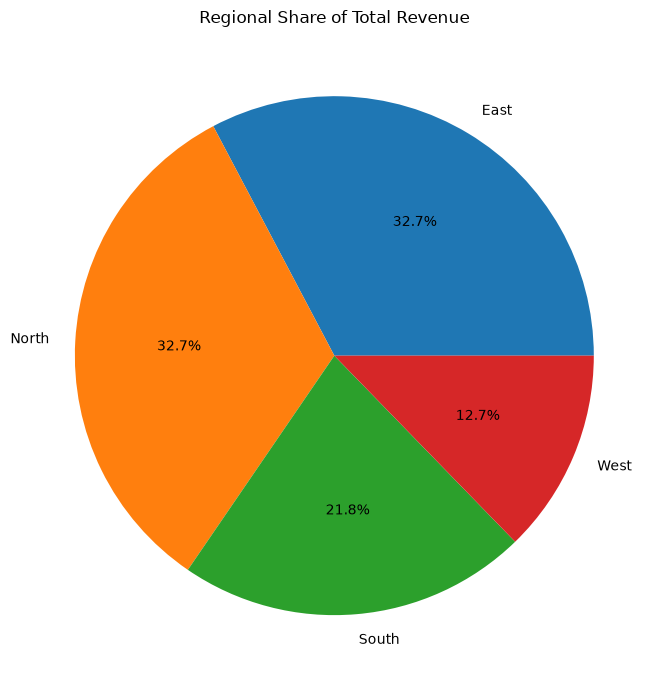

In [14]:
# Plot each region's share of total revenue
region_summary["Revenue_Share_%"].plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    ylabel="",
    title="Regional Share of Total Revenue"
)

plt.tight_layout()
plt.show()

## Key Findings

1. **Overall performance:** The dataset contains 8 transactions, 17 units sold, and total revenue of ₹550,000.
2. **Monthly performance:** April recorded the highest monthly revenue at ₹170,000, while February recorded the lowest at ₹80,000. Revenue fell in February and then increased in March and April.
3. **Product performance:** Laptops generated the highest revenue at ₹300,000. Mobiles sold the most units, with 8 units sold.
4. **Regional performance:** East and North tied for the highest revenue at ₹180,000 each. West recorded the lowest revenue at ₹70,000.
5. **Revenue distribution:** East and North each contributed approximately 32.73% of total revenue.

## Limitations

- The dataset contains only 8 transactions across 4 months.
- The findings describe this dataset and may not represent broader sales patterns.
- The dataset contains revenue information but no costs or expenses, so profit cannot be calculated.
- The data does not establish why sales changed between months or regions.
- More data over a longer period would be needed to identify reliable trends or make forecasts.
